# Problem Statement : Medical Insurence Premium


## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [2]:
data = pd.read_csv('/content/insurance.csv')

In [3]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Data Inspection

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
data.shape

(1338, 7)

In [8]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [9]:
data.duplicated().sum()

1

# EDA

## Univariate Analysis

## Numerical Columns

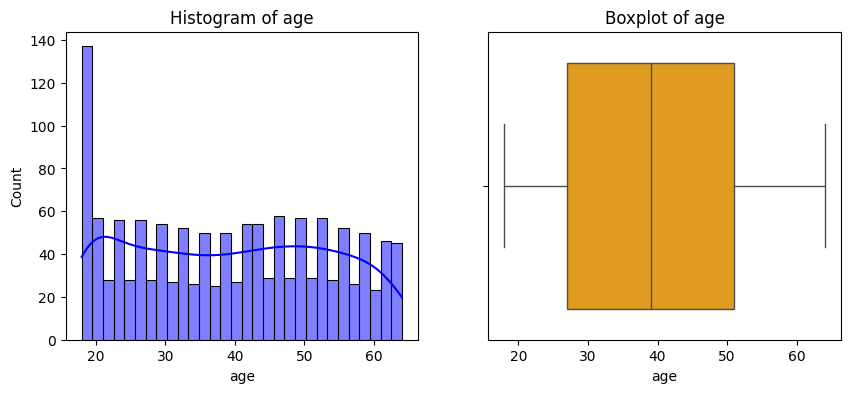

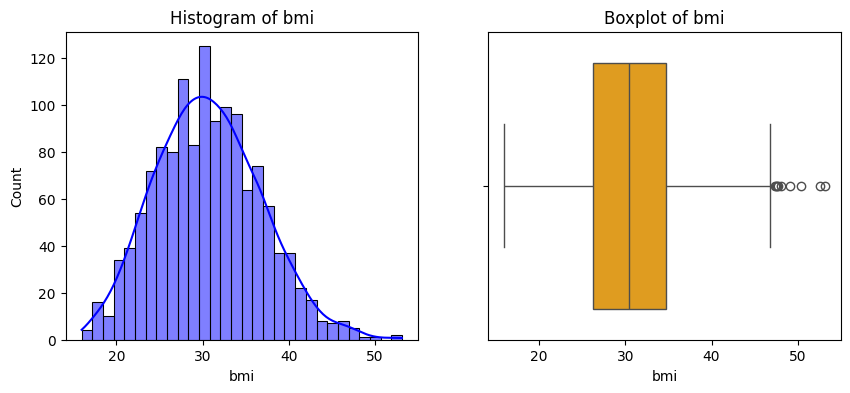

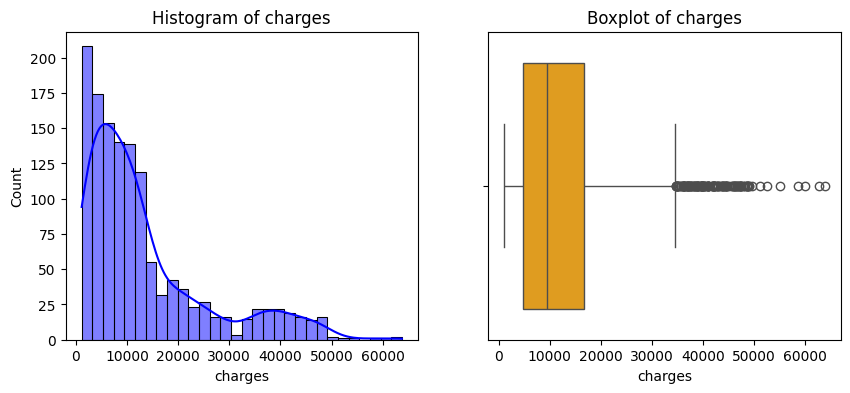

In [29]:
# Plot histograms and boxplots
numeric_features = ['age', 'bmi','charges']

for feature in numeric_features:
    plt.figure(figsize=(10, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(data[feature], kde=True, bins=30, color='blue')
    plt.title(f'Histogram of {feature}')

    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=data[feature], color='orange')
    plt.title(f'Boxplot of {feature}')

    plt.show()


## Categorical Columns

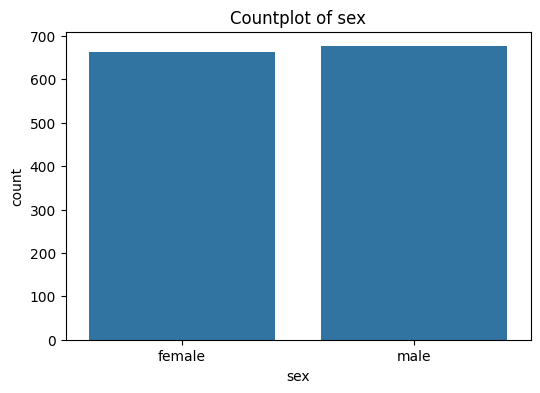

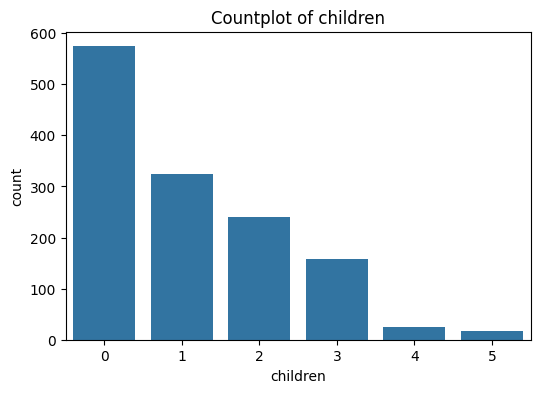

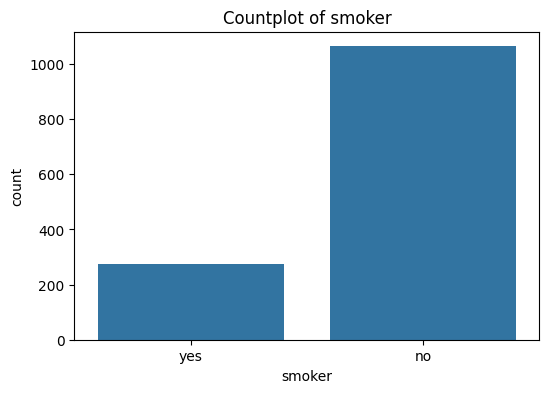

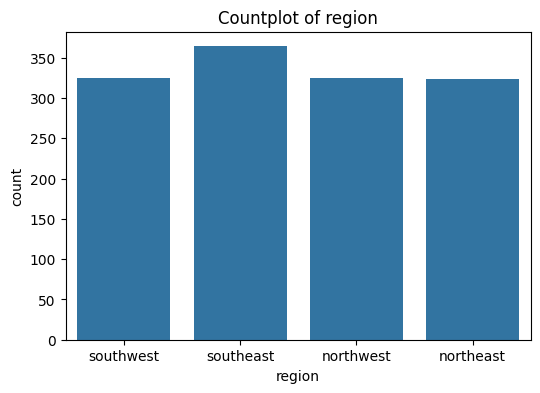

In [31]:
# Plot bar plots
categorical_features = ['sex','children', 'smoker', 'region']

for feature in categorical_features:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=data, x=feature)
    plt.title(f'Countplot of {feature}')
    plt.show()

## Bivariate Analysis

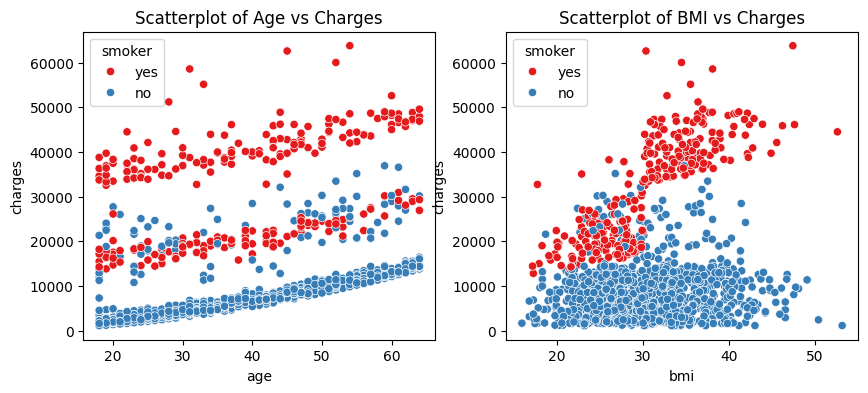

In [36]:
# Scatterplots for charges vs other numeric features
plt.figure(figsize=(10, 4))

plt.subplot(1,2,1)
sns.scatterplot(data=data, x='age', y='charges', hue='smoker', palette='Set1')
plt.title(f'Scatterplot of Age vs Charges')

plt.subplot(1,2,2)
sns.scatterplot(data=data, x='bmi', y='charges', hue='smoker', palette='Set1')
plt.title(f'Scatterplot of BMI vs Charges')

plt.show()

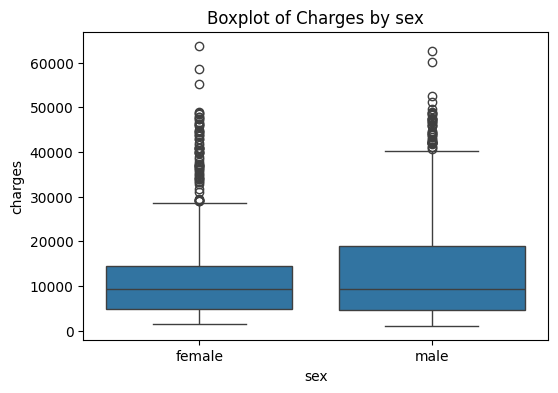

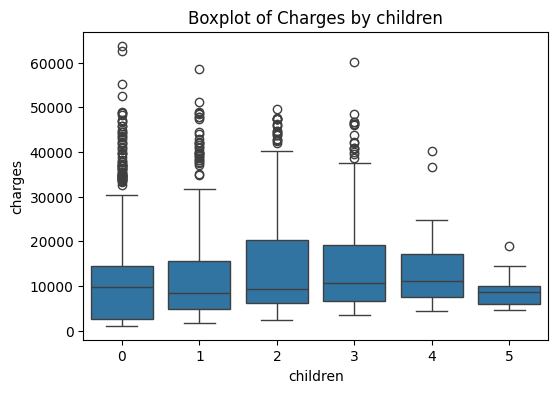

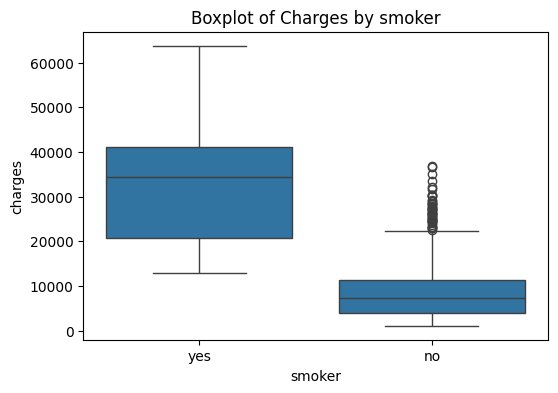

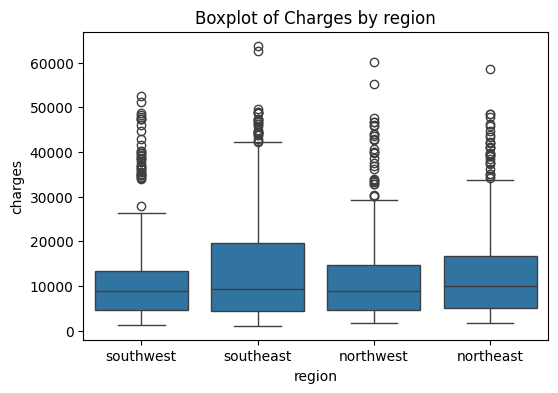

In [38]:
# Boxplots for charges across categories
categorical_features = ['sex','children','smoker', 'region']

for feature in categorical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=data, x=feature, y='charges')
    plt.title(f'Boxplot of Charges by {feature}')
    plt.show()

## One hot encoding

In [39]:
from sklearn.preprocessing import OneHotEncoder

In [80]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [81]:
# apply one hot encoding and replace data
encoded_df = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True).astype(int)
encoded_df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27,0,16884,0,1,0,0,1
1,18,33,1,1725,1,0,0,1,0
2,28,33,3,4449,1,0,0,1,0
3,33,22,0,21984,1,0,1,0,0
4,32,28,0,3866,1,0,1,0,0


## Split Data

In [82]:
X = encoded_df.drop(['charges'], axis = 1)
y = encoded_df['charges']

In [83]:
X

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27,0,0,1,0,0,1
1,18,33,1,1,0,0,1,0
2,28,33,3,1,0,0,1,0
3,33,22,0,1,0,1,0,0
4,32,28,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...
1333,50,30,3,1,0,1,0,0
1334,18,31,0,0,0,0,0,0
1335,18,36,0,0,0,0,1,0
1336,21,25,0,0,0,0,0,1


In [84]:
y

,charges
0,16884
1,1725
2,4449
3,21984
4,3866
...,...
1333,10600
1334,2205
1335,1629
1336,2007


In [85]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [86]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1204, 8)
(134, 8)
(1204,)
(134,)


## Build Multiple Linear Regression Model

In [87]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [88]:
y_pred = lr.predict(X_test)

In [89]:
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

Mean Squared Error: 32201893.448008858


The `Mean Squared Error (MSE)` value of 32,201,893.45 indicates the average squared difference between actual and predicted insurance charges. A large MSE suggests the model might be underperforming or not well-tuned.

## Steps to Improve the Model:

1. `Feature Engineering`: Check for missing important variables or transformations (e.g. log transformation).
2. `Data Scaling`: Ensure numerical features like age, bmi, etc., are scaled properly.
3. `Outlier Treatment`: Remove or handle extreme values that may skew predictions.
4. Try feature selection or regularization.

In [91]:
encoded_df['charges'] = np.log(encoded_df['charges'])
encoded_df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27,0,2.275637,0,1,0,0,1
1,18,33,1,2.008614,1,0,0,1,0
2,28,33,3,2.128283,1,0,0,1,0
3,33,22,0,2.302392,1,0,1,0,0
4,32,28,0,2.111422,1,0,1,0,0


In [92]:
X = encoded_df.drop(['charges'], axis = 1)
y = encoded_df['charges']

In [93]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [94]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [95]:
y_pred = lr.predict(X_test)

In [96]:
y_pred

array([2.21028462, 2.15222177, 2.42450455, 2.2096227 , 2.24321207,
       2.15466879, 2.07375345, 2.26357362, 2.10917179, 2.22564516,
       2.30334108, 2.18529149, 2.12435778, 2.38945116, 2.40834363,
       2.37662214, 2.23290985, 2.37199217, 2.19050045, 2.34110713,
       2.13819526, 2.18803763, 2.06734276, 2.1154733 , 2.23904778,
       2.23296847, 2.24644518, 2.15044679, 2.21959675, 2.06128936,
       2.204091  , 2.2369887 , 2.08811266, 2.14729603, 2.10646415,
       2.19738201, 2.09056088, 2.18203815, 2.38543211, 2.31750698,
       2.13064632, 2.09988395, 2.24188221, 2.2272829 , 2.15035103,
       2.23340869, 2.11940525, 2.12635158, 2.36795063, 2.14651697,
       2.25764652, 2.0712421 , 2.19449392, 2.07235306, 2.21767703,
       2.23029644, 2.11863921, 2.32894304, 2.23576354, 2.23036668,
       2.25288103, 2.15882456, 2.27632145, 2.19047702, 2.22228683,
       2.124926  , 2.2802911 , 2.22480245, 2.10890354, 2.09158232,
       2.1781661 , 2.22384254, 2.19396839, 2.17007032, 2.18682

In [97]:
y_test

,charges
764,2.209974
887,2.148287
890,2.330819
1293,2.212428
259,2.344373
...,...
109,2.375749
575,2.241878
535,2.164543
543,2.403610


In [98]:
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

Mean Squared Error: 0.0022709319776005347


In [99]:
y_pred_original = np.exp(y_pred)
y_pred_original

array([ 9.11831128,  8.6039532 , 11.29663111,  9.11227765,  9.42355179,
        8.62503297,  7.95462446,  9.61739674,  8.24141284,  9.25945471,
       10.0075627 ,  8.89324049,  8.36752193, 10.90750577, 11.1155345 ,
       10.76846701,  9.32696666, 10.71872457,  8.93968589, 10.39273635,
        8.48411216,  8.91769613,  7.9037929 ,  8.29351019,  9.38439105,
        9.32751346,  9.45406851,  8.58869486,  9.20361873,  7.85609261,
        9.06201041,  9.36508772,  8.06967053,  8.56167656,  8.21912826,
        9.00141704,  8.08945109,  8.86435471, 10.86375596, 10.15033774,
        8.42030726,  8.16522228,  9.41102818,  9.27463173,  8.58787248,
        9.33162049,  8.32618399,  8.38422177, 10.6754918 ,  8.55500907,
        9.56056205,  7.93467265,  8.97545763,  7.94349267,  9.18596734,
        9.30262336,  8.31980828, 10.26708394,  9.35362095,  9.30327678,
        9.51510972,  8.66095122,  9.74078246,  8.93947641,  9.22841053,
        8.37227795,  9.77952681,  9.25165495,  8.23920238,  8.09